In [201]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Ukuran gambar: (335, 597, 3)


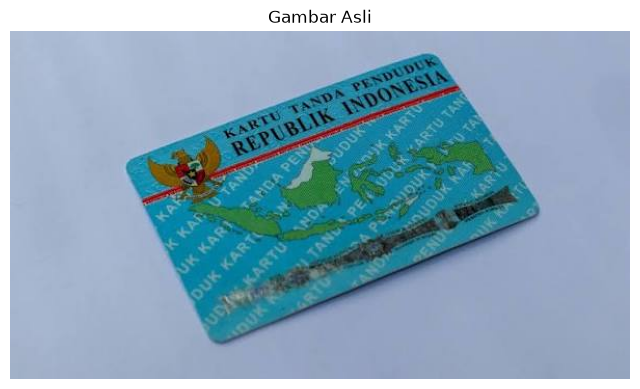

In [202]:
# Membaca gambar
img = cv2.imread("sampel2.jpg")

# Memastikan gambar berhasil dibaca
if img is None:
    raise ValueError("Gambar tidak ditemukan!")

# Menampilkan ukuran gambar
print("Ukuran gambar:", img.shape)

# Mengubah BGR menjadi RGB agar warna benar saat ditampilkan
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Menampilkan gambar asli
plt.figure(figsize=(8, 6))
plt.imshow(img_rgb)
plt.title("Gambar Asli")
plt.axis("off")
plt.show()

In [203]:
pts = np.array([
    [112, 120],  # Top Left
    [410, 20],   # Top Right
    [510, 170],  # Bottom Right
    [195, 300]   # Bottom Left
], dtype=np.float32)

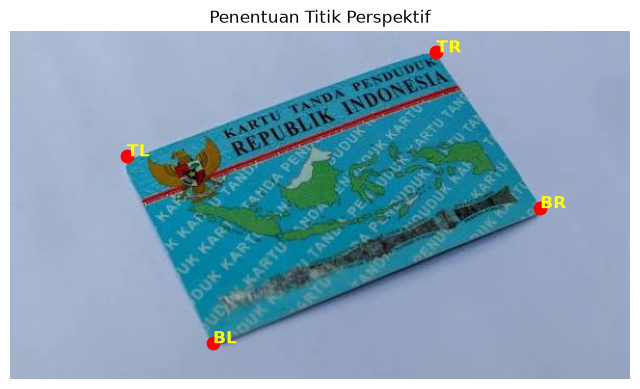

In [204]:
plt.figure(figsize=(8, 10))
plt.imshow(img_rgb)

labels = ["TL", "TR", "BR", "BL"]

for i, point in enumerate(pts):
    x, y = point
    plt.scatter(x, y, color="red", s=80)
    plt.text(
        x, y,
        labels[i],
        color="yellow",
        fontsize=12,
        fontweight="bold"
    )

plt.title("Penentuan Titik Perspektif")
plt.axis("off")
plt.show()

In [205]:
# Fungsi menghitung jarak antara dua titik
def distance(p1, p2):
    return np.linalg.norm(p1 - p2)

# Menghitung lebar objek
width_top = distance(pts[0], pts[1])
width_bottom = distance(pts[3], pts[2])

max_width = int(max(width_top, width_bottom))

# Menghitung tinggi objek
height_left = distance(pts[0], pts[3])
height_right = distance(pts[1], pts[2])

max_height = int(max(height_left, height_right))

print("Lebar hasil:", max_width)
print("Tinggi hasil:", max_height)

Lebar hasil: 340
Tinggi hasil: 198


In [206]:
# Titik tujuan berbentuk persegi panjang
dst = np.array([
    [0, 0],                         # Top Left
    [max_width - 1, 0],              # Top Right
    [max_width - 1, max_height - 1], # Bottom Right
    [0, max_height - 1]              # Bottom Left
], dtype=np.float32)

In [207]:
# Menghitung matriks transformasi perspektif
matrix = cv2.getPerspectiveTransform(pts, dst)

print("Perspective Transform Matrix:")
print(matrix)

Perspective Transform Matrix:
[[ 9.34863788e-01 -4.31076080e-01 -5.29756146e+01]
 [ 3.72386958e-01  1.10971313e+00 -1.74872915e+02]
 [-1.57256728e-04  6.71700489e-04  1.00000000e+00]]


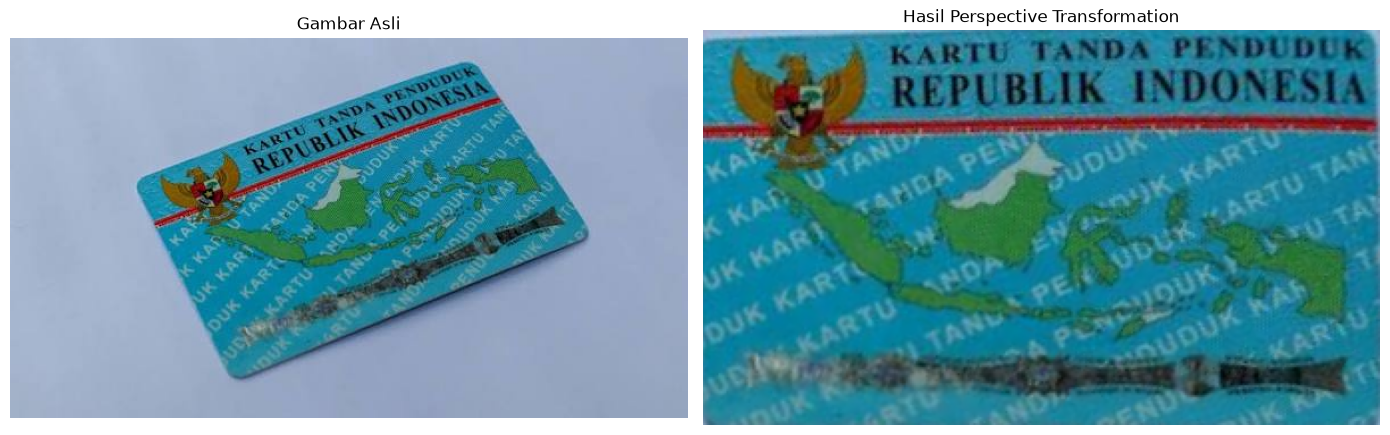

In [ ]:
# Mengubah hasil BGR menjadi RGB
result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Gambar Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result_rgb)
plt.title("Hasil Perspective Transformation")
plt.axis("off")

plt.tight_layout()
plt.show()